<a href="https://colab.research.google.com/github/ranimiftah12345678/ML_22_Ranimiftah/blob/main/JS08/JS08_TUGAS02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Setup

In [4]:
!pip install hdbscan

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hdbscan

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_score, completeness_score)

Load Dataset

In [5]:
iris = load_iris()
X = iris.data
y_true = iris.target
nama_kelas = iris.target_names

print("Bentuk data:", X.shape)
print("Fitur      :", iris.feature_names)
print("Kelas asli :", list(nama_kelas), "-> 50 sampel per kelas")

Bentuk data: (150, 4)
Fitur      : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Kelas asli : [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')] -> 50 sampel per kelas


Standarisasi dan clustering HDBSCAN

In [6]:
X_scaled = StandardScaler().fit_transform(X)

hdb = hdbscan.HDBSCAN(min_cluster_size=5)
hdb.fit(X_scaled)
labels = hdb.labels_

Laporan jumlah cluster dan noise

In [7]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int((labels == -1).sum())

print(f"Jumlah cluster terbentuk : {n_clusters}")
print(f"Banyaknya noise          : {n_noise} dari {len(labels)} sampel ({n_noise/len(labels)*100:.2f}%)")
print("Ukuran tiap cluster      :", dict(zip(*np.unique(labels[labels != -1], return_counts=True))))

Jumlah cluster terbentuk : 2
Banyaknya noise          : 2 dari 150 sampel (1.33%)
Ukuran tiap cluster      : {np.int64(0): np.int64(99), np.int64(1): np.int64(49)}


Visualisasi dengan PCA

Variansi yang dijelaskan PCA: [0.73  0.229] | total: 0.958


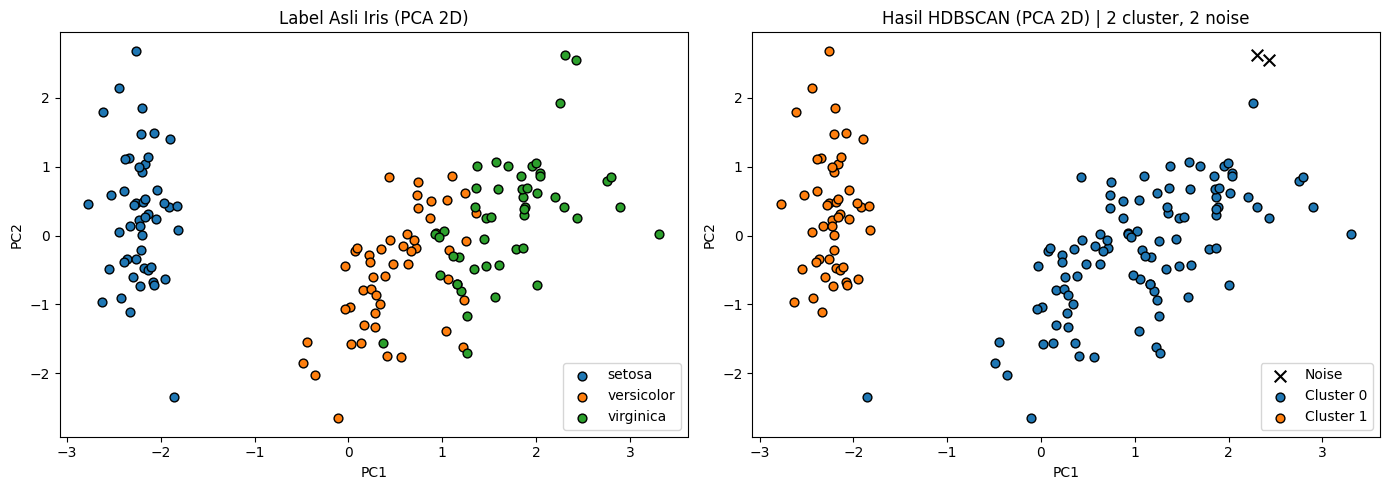

In [8]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("Variansi yang dijelaskan PCA:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Kiri: label asli
for k, nama in enumerate(nama_kelas):
    axes[0].scatter(X_pca[y_true == k, 0], X_pca[y_true == k, 1], label=nama, s=40, edgecolor="k")
axes[0].set_title("Label Asli Iris (PCA 2D)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].legend()

# Kanan: hasil HDBSCAN
for k in sorted(set(labels)):
    m = labels == k
    if k == -1:
        axes[1].scatter(X_pca[m, 0], X_pca[m, 1], c="black", marker="x", s=70, label="Noise")
    else:
        axes[1].scatter(X_pca[m, 0], X_pca[m, 1], s=40, edgecolor="k", label=f"Cluster {k}")
axes[1].set_title(f"Hasil HDBSCAN (PCA 2D) | {n_clusters} cluster, {n_noise} noise")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2"); axes[1].legend()

plt.tight_layout()
plt.show()

Bandingkan dengan label asli

In [9]:
tabel = pd.crosstab(
    pd.Series(y_true).map(dict(enumerate(nama_kelas))).rename("Label asli"),
    pd.Series(labels).map(lambda v: "Noise" if v == -1 else f"Cluster {v}").rename("Hasil HDBSCAN")
)
print(tabel)

print("\nAdjusted Rand Index :", round(adjusted_rand_score(y_true, labels), 4))
print("Normalized MI       :", round(normalized_mutual_info_score(y_true, labels), 4))
print("Homogeneity         :", round(homogeneity_score(y_true, labels), 4))
print("Completeness        :", round(completeness_score(y_true, labels), 4))

Hasil HDBSCAN  Cluster 0  Cluster 1  Noise
Label asli                                
setosa                 1         49      0
versicolor            50          0      0
virginica             48          0      2

Adjusted Rand Index : 0.5394
Normalized MI       : 0.6778
Homogeneity         : 0.554
Completeness        : 0.8728


Pengaruh min_cluster_size (pendukung analisis)

In [10]:
rows = []
for s in [3, 5, 10, 15, 20]:
    l = hdbscan.HDBSCAN(min_cluster_size=s).fit(X_scaled).labels_
    rows.append({"min_cluster_size": s,
                 "jumlah_cluster": len(set(l)) - (1 if -1 in l else 0),
                 "noise": int((l == -1).sum())})
print(pd.DataFrame(rows))

   min_cluster_size  jumlah_cluster  noise
0                 3               2      2
1                 5               2      2
2                10               2      2
3                15               2      4
4                20               2      6
